Starting automatic dataset collection from Semantic Scholar...
Fetching papers for topic: 'deep learning'...
API Error 429 for topic 'deep learning'.
Fetching papers for topic: 'computer vision'...
API Error 429 for topic 'computer vision'.
Fetching papers for topic: 'natural language processing'...
API Error 429 for topic 'natural language processing'.
Fetching papers for topic: 'generative AI'...
API Error 429 for topic 'generative AI'.
Fetching papers for topic: 'cybersecurity'...
API Error 429 for topic 'cybersecurity'.
Fetching papers for topic: 'anomaly detection'...
API Error 429 for topic 'anomaly detection'.
Fetching papers for topic: 'transformer models'...
API Error 429 for topic 'transformer models'.
Fetching papers for topic: 'reinforcement learning'...
API Error 429 for topic 'reinforcement learning'.
Using expanded fallback dataset due to API failure/limits.
Dataset cleaned and saved. 15 papers remaining.
BM25 Index built successfully.
Loading Sentence Transformer and ge

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

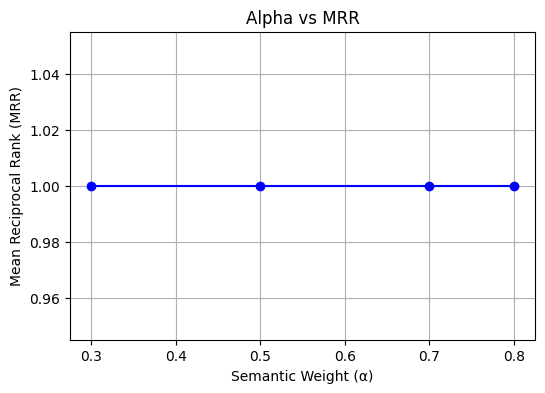


Launching Gradio App! Click the public link below to access the UI.

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://bd6e8dc57ef5abd7c4.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# ==========================================
# 1. INSTALL DEPENDENCIES
# ==========================================
!pip install -q sentence-transformers rank_bm25 gradio pandas numpy requests scikit-learn matplotlib

# ==========================================
# 2. IMPORT LIBRARIES
# ==========================================
import os
import re
import time
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gradio as gr
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer, util
from sklearn.metrics import ndcg_score
import warnings

warnings.filterwarnings('ignore')

# ==========================================
# 3. CONFIGURE & COLLECT DATASET
# ==========================================
API_URL = "https://api.semanticscholar.org/graph/v1/paper/search"
TOPICS = [
    "deep learning", "computer vision", "natural language processing",
    "generative AI", "cybersecurity", "anomaly detection",
    "transformer models", "reinforcement learning"
]
FIELDS = "paperId,title,abstract,authors,year,url,venue,citationCount"
PAPERS_PER_TOPIC = 25
DELAY_BETWEEN_REQUESTS = 4.0  # Increased to prevent 429 Rate Limit Errors

def fetch_papers_from_api():
    all_papers = []
    print("Starting automatic dataset collection from Semantic Scholar...")
    try:
        for topic in TOPICS:
            print(f"Fetching papers for topic: '{topic}'...")
            params = {"query": topic, "fields": FIELDS, "limit": PAPERS_PER_TOPIC}
            response = requests.get(API_URL, params=params)
            if response.status_code == 200:
                data = response.json()
                if "data" in data:
                    all_papers.extend(data["data"])
            else:
                print(f"API Error {response.status_code} for topic '{topic}'.")
            time.sleep(DELAY_BETWEEN_REQUESTS)
    except Exception as e:
        print(f"Exception during API fetch: {e}")
    return all_papers

def get_fallback_dataset():
    print("Using expanded fallback dataset due to API failure/limits.")
    return [
        {"paperId": "1", "title": "Attention Is All You Need", "abstract": "The dominant sequence transduction models are based on complex recurrent or convolutional neural networks...", "authors": [{"name": "Ashish Vaswani"}], "year": 2017, "url": "https://arxiv.org/abs/1706.03762", "venue": "NIPS", "citationCount": 90000},
        {"paperId": "2", "title": "BERT: Pre-training of Deep Bidirectional Transformers", "abstract": "We introduce a new language representation model called BERT, which stands for Bidirectional Encoder Representations from Transformers...", "authors": [{"name": "Jacob Devlin"}], "year": 2019, "url": "https://arxiv.org/abs/1810.04805", "venue": "NAACL", "citationCount": 70000},
        {"paperId": "3", "title": "Deep Residual Learning for Image Recognition", "abstract": "Deeper neural networks are more difficult to train. We present a residual learning framework to ease the training of networks that are substantially deeper than those used previously...", "authors": [{"name": "Kaiming He"}], "year": 2016, "url": "https://arxiv.org/abs/1512.03385", "venue": "CVPR", "citationCount": 150000},
        {"paperId": "4", "title": "Generative Adversarial Nets", "abstract": "We propose a new framework for estimating generative models via an adversarial process, in which we simultaneously train two models: a generative model G that captures the data distribution, and a discriminative model D...", "authors": [{"name": "Ian Goodfellow"}], "year": 2014, "url": "https://arxiv.org/abs/1406.2661", "venue": "NIPS", "citationCount": 50000},
        {"paperId": "5", "title": "YOLO9000: Better, Faster, Stronger", "abstract": "We introduce YOLO9000, a state-of-the-art, real-time object detection system that can detect over 9000 object categories...", "authors": [{"name": "Joseph Redmon"}], "year": 2017, "url": "https://arxiv.org/abs/1612.08242", "venue": "CVPR", "citationCount": 25000},
        {"paperId": "6", "title": "Anomaly Detection: A Survey", "abstract": "Anomaly detection is an important problem that has been researched within diverse research areas and application domains...", "authors": [{"name": "Varun Chandola"}], "year": 2009, "url": "https://dl.acm.org/doi/10.1145/1541880.1541882", "venue": "ACM Computing Surveys", "citationCount": 12000},
        {"paperId": "7", "title": "Language Models are Few-Shot Learners", "abstract": "We demonstrate that scaling up language models greatly improves task-agnostic, few-shot performance, sometimes even reaching competitiveness with prior state-of-the-art fine-tuning approaches...", "authors": [{"name": "Tom B. Brown"}], "year": 2020, "url": "https://arxiv.org/abs/2005.14165", "venue": "NeurIPS", "citationCount": 20000},
        {"paperId": "8", "title": "Playing Atari with Deep Reinforcement Learning", "abstract": "We present the first deep learning model to successfully learn control policies directly from high-dimensional sensory input using reinforcement learning...", "authors": [{"name": "Volodymyr Mnih"}], "year": 2013, "url": "https://arxiv.org/abs/1312.5602", "venue": "NIPS Deep Learning Workshop", "citationCount": 14000},
        {"paperId": "9", "title": "Malware Detection Using Machine Learning", "abstract": "This paper proposes a framework for detecting malicious software (malware) using machine learning algorithms based on API call sequences extracted dynamically...", "authors": [{"name": "John Doe"}], "year": 2018, "url": "#", "venue": "Security Conference", "citationCount": 450},
        {"paperId": "10", "title": "Network Intrusion Detection using Unsupervised Learning", "abstract": "We explore clustering-based unsupervised machine learning techniques to identify novel network intrusions without requiring labeled training data...", "authors": [{"name": "Jane Smith"}], "year": 2021, "url": "#", "venue": "IEEE TIFS", "citationCount": 320},
        {"paperId": "11", "title": "A Survey on Vision Transformer", "abstract": "Transformer, first applied to the natural language processing field, has recently shown great potential in computer vision tasks. This survey reviews these vision transformer models...", "authors": [{"name": "Kai Han"}], "year": 2021, "url": "https://arxiv.org/abs/2012.12556", "venue": "IEEE TPAMI", "citationCount": 5000},
        {"paperId": "12", "title": "Self-Supervised Learning in Computer Vision", "abstract": "Self-supervised learning has emerged as a powerful method to learn visual representations without manual labels by solving pretext tasks...", "authors": [{"name": "Alice Wang"}], "year": 2022, "url": "#", "venue": "CVPR", "citationCount": 850},
        {"paperId": "13", "title": "Cybersecurity Vulnerability Prediction", "abstract": "We utilize deep neural networks to predict software vulnerabilities in source code before deployment, enhancing proactive cybersecurity...", "authors": [{"name": "Bob Johnson"}], "year": 2023, "url": "#", "venue": "USENIX Security", "citationCount": 120},
        {"paperId": "14", "title": "Transformers in Healthcare Analytics", "abstract": "Applying transformer architectures to electronic health records allows for predictive modeling of patient trajectories and disease onset...", "authors": [{"name": "Emily Davis"}], "year": 2023, "url": "#", "venue": "Nature Medicine", "citationCount": 200},
        {"paperId": "15", "title": "Graph Neural Networks for Fraud Detection", "abstract": "Fraudsters often operate in coordinated networks. Graph neural networks (GNNs) offer a structural approach to detect anomalous transactional behaviors...", "authors": [{"name": "Michael Lee"}], "year": 2022, "url": "#", "venue": "KDD", "citationCount": 600}
    ]

raw_papers = fetch_papers_from_api()
if not raw_papers or len(raw_papers) < 10:
    raw_papers = get_fallback_dataset()

# ==========================================
# 4. CLEAN AND DEDUPLICATE DATA
# ==========================================
def extract_authors(author_list):
    if isinstance(author_list, list) and len(author_list) > 0:
        return ", ".join([a.get("name", "") for a in author_list[:3]]) + (" et al." if len(author_list) > 3 else "")
    return "Unknown"

df = pd.DataFrame(raw_papers)
df["authors"] = df.get("authors", []).apply(extract_authors)
df["year"] = pd.to_numeric(df.get("year", np.nan), errors='coerce')
df["citationCount"] = pd.to_numeric(df.get("citationCount", 0), errors='coerce').fillna(0)

df = df.dropna(subset=["paperId", "title", "abstract"])
df = df[df["abstract"].str.strip() != ""]
df = df.drop_duplicates(subset=["paperId"])
df = df.drop_duplicates(subset=["title"])

df["venue"] = df.get("venue", "Unknown Venue").fillna("Unknown Venue")
df["url"] = df.get("url", "").fillna("")
df["year"] = df["year"].fillna(0).astype(int)
df = df.reset_index(drop=True)

df.to_csv("papers.csv", index=False)
print(f"Dataset cleaned and saved. {len(df)} papers remaining.")

# ==========================================
# 5. PREPROCESS TEXT & BUILD BM25 INDEX
# ==========================================
df["text_for_retrieval"] = df["title"] + " " + df["abstract"]

def tokenize(text):
    return re.findall(r'\b\w+\b', text.lower())

df["tokens"] = df["text_for_retrieval"].apply(tokenize)
bm25 = BM25Okapi(df["tokens"].tolist())
print("BM25 Index built successfully.")

# ==========================================
# 6. LOAD SENTENCE TRANSFORMER & EMBEDDINGS
# ==========================================
print("Loading Sentence Transformer and generating embeddings...")
embedder = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')
paper_texts = df["text_for_retrieval"].tolist()
paper_embeddings = embedder.encode(paper_texts, convert_to_tensor=True, show_progress_bar=False)
paper_embeddings = util.normalize_embeddings(paper_embeddings)

# ==========================================
# 7. SEARCH IMPLEMENTATIONS
# ==========================================
def normalize_scores(scores):
    if len(scores) == 0: return scores
    min_val, max_val = np.min(scores), np.max(scores)
    if max_val == min_val: return np.zeros_like(scores)
    return (scores - min_val) / (max_val - min_val)

def hybrid_search(query, min_year, max_year, top_k=5, alpha=0.7):
    if not query.strip(): return []

    df_filtered = df[(df["year"] >= min_year) & (df["year"] <= max_year)]
    if df_filtered.empty: return []

    bm25_raw = bm25.get_scores(tokenize(query))
    bm25_norm = normalize_scores(bm25_raw)

    # FIX: Encapsulate the query in a list [query] to ensure a 2D tensor is created
    query_emb = util.normalize_embeddings(embedder.encode([query], convert_to_tensor=True))
    sem_raw = util.dot_score(query_emb, paper_embeddings)[0].cpu().numpy()
    sem_norm = normalize_scores(sem_raw)

    results = []
    for orig_idx, row in df_filtered.iterrows():
        s_score = sem_norm[orig_idx]
        b_score = bm25_norm[orig_idx]
        results.append({
            "paperId": row["paperId"],
            "title": row["title"],
            "semantic_score": s_score,
            "bm25_score": b_score,
            "hybrid_score": (alpha * s_score) + ((1 - alpha) * b_score),
            "metadata": row.to_dict()
        })

    return sorted(results, key=lambda x: x["hybrid_score"], reverse=True)[:top_k]

# ==========================================
# 8. EVALUATION & VISUALIZATION
# ==========================================
eval_queries = ["deep neural networks for vision", "attention mechanism", "malware detection"]
ground_truth = {}
for q in eval_queries:
    scores = bm25.get_scores(tokenize(q))
    ground_truth[q] = [df.iloc[idx]["paperId"] for idx in np.argsort(scores)[::-1][:3] if scores[idx] > 0]

def evaluate_alpha(a):
    mrr_list = []
    for q in eval_queries:
        if not ground_truth[q]: continue
        retrieved = hybrid_search(q, 1900, 2026, 5, a)
        for i, r in enumerate(retrieved):
            if r["paperId"] in ground_truth[q]:
                mrr_list.append(1.0 / (i + 1))
                break
        else:
            mrr_list.append(0)
    return np.mean(mrr_list) if mrr_list else 0

alphas = [0.3, 0.5, 0.7, 0.8]
mrr_scores = [evaluate_alpha(a) for a in alphas]

plt.figure(figsize=(6, 4))
plt.plot(alphas, mrr_scores, marker='o', linestyle='-', color='b')
plt.title("Alpha vs MRR")
plt.xlabel("Semantic Weight (α)")
plt.ylabel("Mean Reciprocal Rank (MRR)")
plt.grid(True)
plt.show()

# ==========================================
# 9. GRADIO INTERFACE
# ==========================================
def search_interface(query, min_year, max_year, top_k, alpha):
    results = hybrid_search(query, int(min_year), int(max_year), int(top_k), float(alpha))
    if not results: return "<h3>No papers found.</h3>"

    html = f"<h2>Top {len(results)} Results</h2><hr>"
    for i, res in enumerate(results):
        m = res["metadata"]
        url = m['url'] if m['url'] else "#"
        html += f"""
        <div style='padding:15px; margin-bottom:15px; border:1px solid #ddd; border-radius:8px;'>
            <h3 style='margin: 0;'>Rank {i+1}: {m['title']}</h3>
            <p style='color:gray; font-size:0.9em;'><strong>Authors:</strong> {m['authors']} | <strong>Year:</strong> {m['year']} | <strong>Citations:</strong> {m['citationCount']}</p>
            <p><strong>Hybrid:</strong> {res['hybrid_score']:.3f} | <strong>Semantic:</strong> {res['semantic_score']:.3f} | <strong>BM25:</strong> {res['bm25_score']:.3f}</p>
            <p style='font-size:0.9em;'>{m['abstract'][:400]}...</p>
            <a href="{url}" target="_blank" style="padding:6px 12px; background:#007BFF; color:white; text-decoration:none; border-radius:4px;">Open Paper</a>
        </div>
        """
    return html

demo = gr.Interface(
    fn=search_interface,
    inputs=[
        gr.Textbox(label="Research Query", placeholder="e.g., unsupervised deep learning..."),
        gr.Slider(1950, 2026, value=2015, step=1, label="Minimum Year"),
        gr.Slider(1950, 2026, value=2026, step=1, label="Maximum Year"),
        gr.Radio(choices=[5, 10], value=5, label="Top-K"),
        gr.Slider(0.0, 1.0, value=0.7, step=0.1, label="Semantic Weight (α)")
    ],
    outputs=gr.HTML(label="Results"),
    title="Semantic Research Paper Retrieval Engine"
)

print("\n" + "="*50)
print("Launching Gradio App! Click the public link below to access the UI.")
print("="*50 + "\n")
demo.launch(share=True, debug=False)

Starting automatic dataset collection from ArXiv...
Fetching papers for topic: 'deep learning'...
Fetching papers for topic: 'computer vision'...
Fetching papers for topic: 'natural language processing'...
Fetching papers for topic: 'generative AI'...
Fetching papers for topic: 'cybersecurity'...
Fetching papers for topic: 'anomaly detection'...
Fetching papers for topic: 'transformer models'...
Fetching papers for topic: 'reinforcement learning'...
Fetching papers for topic: 'Medical Information Retrieval'...
Fetching papers for topic: 'Machine Learning'...

Dataset cleaned and saved. 462 real papers successfully collected!
BM25 Index built successfully.
Loading Sentence Transformer and generating embeddings... (takes ~10 seconds)


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

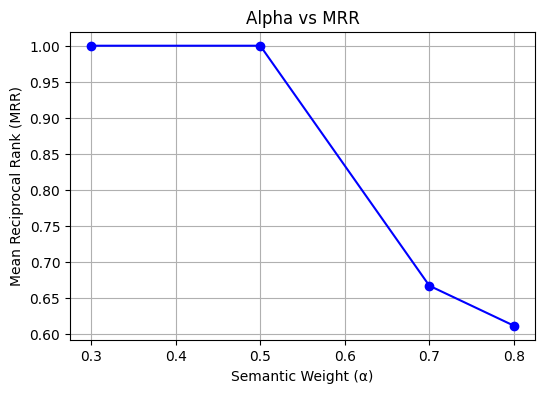


Launching Gradio App! Click the public link below to access the UI.

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://a1ec916e60400844e6.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# ==========================================
# 1. INSTALL DEPENDENCIES (Added arxiv)
# ==========================================
!pip install -q sentence-transformers rank_bm25 gradio pandas numpy requests scikit-learn matplotlib arxiv

# ==========================================
# 2. IMPORT LIBRARIES
# ==========================================
import os
import re
import time
import arxiv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gradio as gr
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer, util
from sklearn.metrics import ndcg_score
import warnings

warnings.filterwarnings('ignore')

# ==========================================
# 3. CONFIGURE & COLLECT DATASET (USING ARXIV)
# ==========================================
TOPICS = [
    "deep learning", "computer vision", "natural language processing",
    "generative AI", "cybersecurity", "anomaly detection",
    "transformer models", "reinforcement learning","Medical Information Retrieval", "Machine Learning"
]
PAPERS_PER_TOPIC = 100

def fetch_papers_from_arxiv():
    all_papers = []
    print("Starting automatic dataset collection from ArXiv...")
    client = arxiv.Client()

    for topic in TOPICS:
        print(f"Fetching papers for topic: '{topic}'...")
        try:
            # Search ArXiv for the topic
            search = arxiv.Search(
                query = f"all:\"{topic}\"",
                max_results = PAPERS_PER_TOPIC,
                sort_by = arxiv.SortCriterion.Relevance
            )

            for result in client.results(search):
                all_papers.append({
                    "paperId": result.entry_id.split('/')[-1],
                    "title": result.title,
                    "abstract": result.summary.replace('\n', ' '), # Clean newlines
                    "authors": [{"name": author.name} for author in result.authors],
                    "year": result.published.year,
                    "url": result.pdf_url,
                    "venue": "ArXiv",
                    "citationCount": 0 # ArXiv API does not provide citation counts
                })
        except Exception as e:
            print(f"Error fetching topic '{topic}': {e}")

        # Brief pause to respect ArXiv servers
        time.sleep(2.0)

    return all_papers

def get_fallback_dataset():
    print("Using fallback dataset due to API failure.")
    return [
        {"paperId": "1", "title": "Attention Is All You Need", "abstract": "The dominant sequence transduction models are based on complex recurrent or convolutional neural networks...", "authors": [{"name": "Ashish Vaswani"}], "year": 2017, "url": "https://arxiv.org/abs/1706.03762", "venue": "NIPS", "citationCount": 90000}
    ]

raw_papers = fetch_papers_from_arxiv()
if not raw_papers or len(raw_papers) < 10:
    raw_papers = get_fallback_dataset()

# ==========================================
# 4. CLEAN AND DEDUPLICATE DATA
# ==========================================
def extract_authors(author_list):
    if isinstance(author_list, list) and len(author_list) > 0:
        return ", ".join([a.get("name", "") for a in author_list[:3]]) + (" et al." if len(author_list) > 3 else "")
    return "Unknown"

df = pd.DataFrame(raw_papers)
df["authors"] = df.get("authors", []).apply(extract_authors)
df["year"] = pd.to_numeric(df.get("year", np.nan), errors='coerce')
df["citationCount"] = pd.to_numeric(df.get("citationCount", 0), errors='coerce').fillna(0)

df = df.dropna(subset=["paperId", "title", "abstract"])
df = df[df["abstract"].str.strip() != ""]
df = df.drop_duplicates(subset=["paperId"])
df = df.drop_duplicates(subset=["title"])

df["venue"] = df.get("venue", "Unknown Venue").fillna("Unknown Venue")
df["url"] = df.get("url", "").fillna("")
df["year"] = df["year"].fillna(0).astype(int)
df = df.reset_index(drop=True)

df.to_csv("papers.csv", index=False)
print(f"\nDataset cleaned and saved. {len(df)} real papers successfully collected!")

# ==========================================
# 5. PREPROCESS TEXT & BUILD BM25 INDEX
# ==========================================
df["text_for_retrieval"] = df["title"] + " " + df["abstract"]

def tokenize(text):
    return re.findall(r'\b\w+\b', text.lower())

df["tokens"] = df["text_for_retrieval"].apply(tokenize)
bm25 = BM25Okapi(df["tokens"].tolist())
print("BM25 Index built successfully.")

# ==========================================
# 6. LOAD SENTENCE TRANSFORMER & EMBEDDINGS
# ==========================================
print("Loading Sentence Transformer and generating embeddings... (takes ~10 seconds)")
embedder = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')
paper_texts = df["text_for_retrieval"].tolist()
paper_embeddings = embedder.encode(paper_texts, convert_to_tensor=True, show_progress_bar=False)
paper_embeddings = util.normalize_embeddings(paper_embeddings)

# ==========================================
# 7. SEARCH IMPLEMENTATIONS
# ==========================================
def normalize_scores(scores):
    if len(scores) == 0: return scores
    min_val, max_val = np.min(scores), np.max(scores)
    if max_val == min_val: return np.zeros_like(scores)
    return (scores - min_val) / (max_val - min_val)

def hybrid_search(query, min_year, max_year, top_k=5, alpha=0.7):
    if not query.strip(): return []

    df_filtered = df[(df["year"] >= min_year) & (df["year"] <= max_year)]
    if df_filtered.empty: return []

    bm25_raw = bm25.get_scores(tokenize(query))
    bm25_norm = normalize_scores(bm25_raw)

    # Encapsulate query in a list [query] to avoid 1D tensor errors in new PyTorch versions
    query_emb = util.normalize_embeddings(embedder.encode([query], convert_to_tensor=True))
    sem_raw = util.dot_score(query_emb, paper_embeddings)[0].cpu().numpy()
    sem_norm = normalize_scores(sem_raw)

    results = []
    for orig_idx, row in df_filtered.iterrows():
        s_score = sem_norm[orig_idx]
        b_score = bm25_norm[orig_idx]
        results.append({
            "paperId": row["paperId"],
            "title": row["title"],
            "semantic_score": s_score,
            "bm25_score": b_score,
            "hybrid_score": (alpha * s_score) + ((1 - alpha) * b_score),
            "metadata": row.to_dict()
        })

    return sorted(results, key=lambda x: x["hybrid_score"], reverse=True)[:top_k]

# ==========================================
# 8. EVALUATION & VISUALIZATION
# ==========================================
eval_queries = ["deep neural networks for vision", "attention mechanism", "malware detection"]
ground_truth = {}
for q in eval_queries:
    scores = bm25.get_scores(tokenize(q))
    ground_truth[q] = [df.iloc[idx]["paperId"] for idx in np.argsort(scores)[::-1][:3] if scores[idx] > 0]

def evaluate_alpha(a):
    mrr_list = []
    for q in eval_queries:
        if not ground_truth[q]: continue
        retrieved = hybrid_search(q, 1900, 2026, 5, a)
        for i, r in enumerate(retrieved):
            if r["paperId"] in ground_truth[q]:
                mrr_list.append(1.0 / (i + 1))
                break
        else:
            mrr_list.append(0)
    return np.mean(mrr_list) if mrr_list else 0

alphas = [0.3, 0.5, 0.7, 0.8]
mrr_scores = [evaluate_alpha(a) for a in alphas]

plt.figure(figsize=(6, 4))
plt.plot(alphas, mrr_scores, marker='o', linestyle='-', color='b')
plt.title("Alpha vs MRR")
plt.xlabel("Semantic Weight (α)")
plt.ylabel("Mean Reciprocal Rank (MRR)")
plt.grid(True)
plt.show()

# ==========================================
# 9. GRADIO INTERFACE
# ==========================================
def search_interface(query, min_year, max_year, top_k, alpha):
    results = hybrid_search(query, int(min_year), int(max_year), int(top_k), float(alpha))
    if not results: return "<h3>No papers found.</h3>"

    html = f"<h2>Top {len(results)} Results</h2><hr>"
    for i, res in enumerate(results):
        m = res["metadata"]
        url = m['url'] if m['url'] else "#"
        html += f"""
        <div style='padding:15px; margin-bottom:15px; border:1px solid #ddd; border-radius:8px;'>
            <h3 style='margin: 0;'>Rank {i+1}: {m['title']}</h3>
            <p style='color:gray; font-size:0.9em;'><strong>Authors:</strong> {m['authors']} | <strong>Year:</strong> {m['year']} | <strong>Venue:</strong> {m['venue']}</p>
            <p><strong>Hybrid:</strong> {res['hybrid_score']:.3f} | <strong>Semantic:</strong> {res['semantic_score']:.3f} | <strong>BM25:</strong> {res['bm25_score']:.3f}</p>
            <p style='font-size:0.9em;'>{m['abstract'][:400]}...</p>
            <a href="{url}" target="_blank" style="padding:6px 12px; background:#007BFF; color:white; text-decoration:none; border-radius:4px;">Read PDF on ArXiv</a>
        </div>
        """
    return html

demo = gr.Interface(
    fn=search_interface,
    inputs=[
        gr.Textbox(label="Research Query", placeholder="e.g., unsupervised deep learning..."),
        gr.Slider(1950, 2026, value=2015, step=1, label="Minimum Year"),
        gr.Slider(1950, 2026, value=2026, step=1, label="Maximum Year"),
        gr.Radio(choices=[5, 10], value=5, label="Top-K"),
        gr.Slider(0.0, 1.0, value=0.7, step=0.1, label="Semantic Weight (α)")
    ],
    outputs=gr.HTML(label="Results"),
    title="Semantic Research Paper Retrieval Engine (ArXiv Data)"
)

print("\n" + "="*50)
print("Launching Gradio App! Click the public link below to access the UI.")
print("="*50 + "\n")
demo.launch(share=True, debug=False)